<a href="https://colab.research.google.com/github/gmandl10/BU425-Group-Project/blob/main/Event_Study_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving data.csv to data.csv


In [ ]:
!ls


data.csv  sample_data


In [ ]:
import pandas as pd
data = pd.read_csv("data.csv")
print("Column Names in the Dataset:")
print(data.columns.tolist())


Column Names in the Dataset:
['Organization Name', 'Organization Name URL', 'Industries', 'Headquarters Location', 'Description', 'Operating Status', 'Last Funding Date', 'Total Funding Amount', 'Total Funding Amount Currency', 'Total Funding Amount  in USD ', 'Last Funding Amount', 'Last Funding Amount Currency', 'Last Funding Amount  in USD ', 'Funding Status', 'Last Funding Type', 'Full Description', 'Sector', 'year month', 'Unemployment Rate', 'Interest Rate', 'Bond Spread', 'VIX Index', 'Treasury Yield Spread', 'SPX Close', 'SPX Volume']


In [ ]:
import os
print(os.getcwd())


/content


## Stationary Tests, VIF Macro Variables, Arima Model, Arch Effect --> GARCH Modelling

---



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 985.1/985.1 kB 36.1 MB/s eta 0:00:00
ADF Test for Unemployment Rate: p-value = 0.22104007048035657
Unemployment Rate is non-stationary. Differencing applied.
ADF Test for Interest Rate: p-value = 0.001501870726993406
ADF Test for Bond Spread: p-value = 0.00023262280772116893
ADF Test for VIX Index: p-value = 0.00013463906211186536
ADF Test for Treasury Yield Spread: p-value = 0.004032387093891039
ADF Test for SPX Close: p-value = 0.2059243719528615
SPX Close is non-stationary. Differencing applied.
ADF Test for SPX Volume: p-value = 3.4495038887148247e-15
VIF Values:
                 Variable        VIF
0      Unemployment Rate   1.017317
1          Interest Rate   2.718322
2            Bond Spread  22.348883
3              VIX Index  11.879803
4  Treasury Yield Spread   9.759433
5              SPX Close   1.071576
6             SPX Volume  22.673187
Variables remove

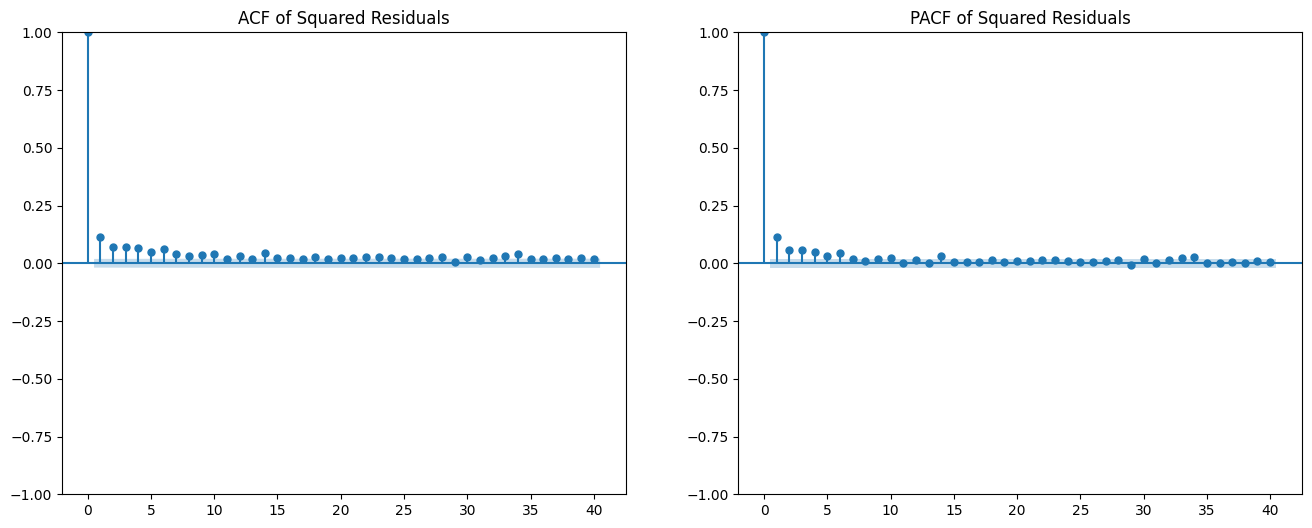

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                      y   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -21647.1
Distribution:                  Normal   AIC:                           43302.2
Method:            Maximum Likelihood   BIC:                           43331.3
                                        No. Observations:                10856
Date:                Mon, Dec 02 2024   Df Residuals:                    10855
Time:                        15:06:20   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu            -0.0289  1.699e-02     -1.700  8.908e-02 

In [ ]:
!pip install pmdarima arch

import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.utils import resample
from scipy.stats import mannwhitneyu
from pmdarima import auto_arima
from arch import arch_model
from statsmodels.tsa.stattools import adfuller
import warnings
warnings.filterwarnings("ignore")

# Load the dataset
data = pd.read_csv("data.csv")
data['Last Funding Date'] = pd.to_datetime(data['Last Funding Date'])

# Define the macroeconomic variables and fill NA
macro_vars = [
    'Unemployment Rate',
    'Interest Rate',
    'Bond Spread',
    'VIX Index',
    'Treasury Yield Spread',
    'SPX Close',
    'SPX Volume'
]
data[macro_vars] = data[macro_vars].fillna(method='ffill')

# Ensure exogenous variables are stationary
stationary_exog = pd.DataFrame()
for col in macro_vars:
    result = adfuller(data[col].dropna())
    print(f"ADF Test for {col}: p-value = {result[1]}")
    if result[1] > 0.05:
        print(f"{col} is non-stationary. Differencing applied.")
        stationary_exog[col] = data[col].diff().fillna(0)  # Differencing
    else:
        stationary_exog[col] = data[col]  # Already stationary

# Check multicollinearity using VIF
X = stationary_exog.dropna().values  # Ensure no missing values for VIF calculation
vif_data = pd.DataFrame()
vif_data['Variable'] = stationary_exog.columns
vif_data['VIF'] = [variance_inflation_factor(X, i) for i in range(X.shape[1])]
print("VIF Values:\n", vif_data)

# Remove variables with high VIF (> 5)
high_vif_vars = vif_data[vif_data['VIF'] > 5]['Variable']
stationary_exog = stationary_exog.drop(columns=high_vif_vars)
print("Variables removed due to high VIF:", high_vif_vars.tolist())

# Define ARIMA inputs
data['log_Last_Funding_Amount'] = np.log(data['Last Funding Amount'] + 1)
funding_ts = data['log_Last_Funding_Amount'].dropna().values
exog_vars = stationary_exog.dropna().values  # Ensure match

# Perform ADF test on the target time series
result = adfuller(funding_ts)
print(f"ADF Statistic: {result[0]}")
print(f"P-value: {result[1]}")

if result[1] > 0.05:
    print("The series is non-stationary. Differencing will be applied.")
    funding_ts = np.diff(funding_ts, n=1)  # Apply first differencing
else:
    print("The series is stationary. Proceed with modeling.")

# Perform ADF test on exogenous variables
for col in macro_vars:
    result = adfuller(data[col].dropna())
    print(f"ADF Test for {col}: p-value = {result[1]}")
    if result[1] > 0.05:
        print(f"{col} is non-stationary. Differencing will be applied.")
        data[col] = data[col].diff().fillna(0)  # Apply differencing


# Automatically select ARIMA order and fit the model
auto_arima_model = auto_arima(
    funding_ts,
    exogenous=exog_vars,
    seasonal=False,
    stepwise=True,
    trace=True
)

# Print the best ARIMA order
print("Best ARIMA Order Selected:", auto_arima_model.order)
#Extract residuals from the ARIMA model
residuals = auto_arima_model.resid()

from statsmodels.stats.diagnostic import het_arch

# ARCH effect test on ARIMA residuals (Even if residuals pass the Ljung-Box and Jarque-Bera tests, they might still exhibit conditional heteroskedasticity (varying volatility over time))
arch_pvalue = het_arch(residuals)[1]
print(f"ARCH Effect Test P-value: {arch_pvalue}")

# Interpretation
if arch_pvalue < 0.05:
    print("ARCH effect detected. Proceed with GARCH modeling.")
else:
    print("No ARCH effect detected. GARCH modeling may not be necessary.")


# Diagnostic checks
print("Ljung-Box Test:", acorr_ljungbox(residuals, lags=[10], return_df=True))
print("Jarque-Bera Test:", jarque_bera(residuals))

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

# Squared residuals for ACF/PACF
squared_residuals = residuals ** 2

# ACF and PACF plots
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_acf(squared_residuals, lags=40, ax=ax[0], title="ACF of Squared Residuals")
plot_pacf(squared_residuals, lags=40, ax=ax[1], title="PACF of Squared Residuals")
plt.show()


# Fit GARCH model to the ARIMA residuals
garch_model = arch_model(residuals, vol='Garch', p=1, q=1)
garch_results = garch_model.fit(disp="off")

# Print summary of the GARCH model
print(garch_results.summary())

print("Post-GARCH Ljung-Box Test:", acorr_ljungbox(garch_results.resid, lags=[10], return_df=True))

# Extract conditional volatilities for all time points
conditional_volatilities = garch_results.conditional_volatility

# Define QE event dates and windows
event_dates = {
    'QE1 Initial': '2008-11-25',
    'QE1 Expansion': '2009-03-18',
    'QE2 Announcement': '2010-11-03',
    'QE2 Operation Twist': '2011-09-21',
    'QE3 Initial': '2012-09-13',
    'QE3 Expansion': '2012-12-12'
}
event_dates = {k: pd.to_datetime(v) for k, v in event_dates.items()}
event_windows = [30, 60, 90, 120]


Plot: Log Funding amounts

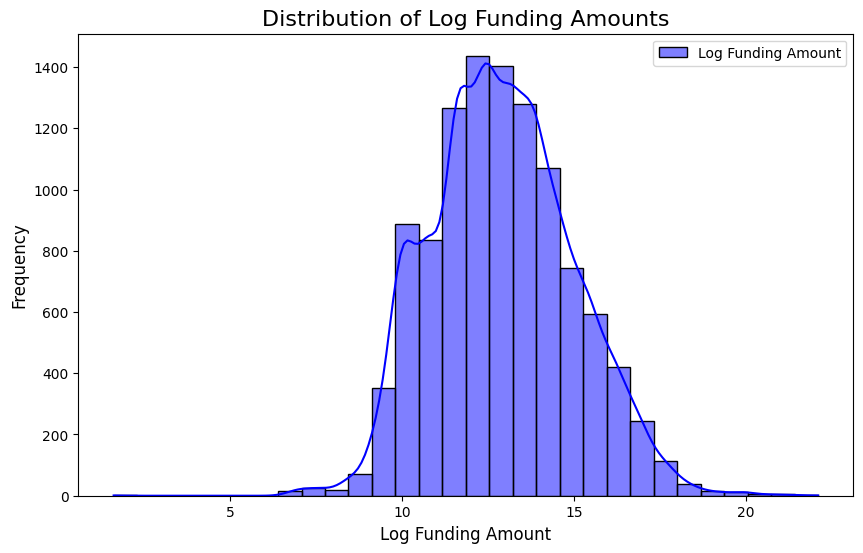

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of log funding amounts
plt.figure(figsize=(10, 6))

# Histogram with Kernel Density Estimation (KDE)
sns.histplot(data['log_Last_Funding_Amount'], kde=True, color="blue", bins=30, label="Log Funding Amount")

# Add title and labels
plt.title("Distribution of Log Funding Amounts", fontsize=16)
plt.xlabel("Log Funding Amount", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend()

# Show the plot
plt.show()


1. Event Study

In [ ]:
from scipy.stats import ttest_ind


# Placeholder for results
results = []

# Loop over each event, window, sector, and funding type
for event_name, event_date in event_dates.items():
    for window in event_windows:
        # Analyze by Sector
        for sector in data['Sector'].unique():
            sector_data = data[data['Sector'] == sector]

            # Pre- and post-event data
            pre_event_data = sector_data[
                (sector_data['Last Funding Date'] >= event_date - pd.Timedelta(days=window)) &
                (sector_data['Last Funding Date'] < event_date)
            ]['log_Last_Funding_Amount']

            post_event_data = sector_data[
                (sector_data['Last Funding Date'] >= event_date) &
                (sector_data['Last Funding Date'] <= event_date + pd.Timedelta(days=window))
            ]['log_Last_Funding_Amount']

            if len(pre_event_data) >= 2 and len(post_event_data) >= 2:
                # Predict pre-event and post-event data using ARIMA
                pre_event_pred = auto_arima_model.predict_in_sample(end=len(pre_event_data) - 1)
                post_event_pred = auto_arima_model.predict(
                    n_periods=len(post_event_data),
                    X=exog_vars[len(pre_event_data):]
                )

                # Extract corresponding GARCH conditional volatilities
                pre_event_var = conditional_volatilities[:len(pre_event_data)]
                post_event_var = conditional_volatilities[len(pre_event_data):len(pre_event_data) + len(post_event_data)]

                # Adjust CAR using GARCH variance
                adjusted_post_event = (post_event_data - post_event_pred) / post_event_var
                adjusted_pre_event = (pre_event_data - pre_event_pred) / pre_event_var

                # Calculate CAR and CAAR
                car = adjusted_post_event.sum()
                caar = adjusted_post_event.mean()

                # Additional Tests
                # Mann-Whitney U Test
                mannwhitney_p = mannwhitneyu(pre_event_data.values, post_event_data.values, alternative='two-sided')[1]

                # Patell Z-Test approximation
                patell_z = (adjusted_post_event.mean() - adjusted_pre_event.mean()) / adjusted_post_event.std()

                # Welch’s t-test for eta-squared
                t_stat, p_value = ttest_ind(pre_event_data.values, post_event_data.values, equal_var=False)
                eta_squared = t_stat**2 / (t_stat**2 + len(pre_event_data) + len(post_event_data) - 2)

                # Bootstrap CAR for confidence intervals
                bootstrap_cars = []
                for _ in range(1000):
                    pre_sample = resample(pre_event_data.values, replace=True)
                    post_sample = resample(post_event_data.values, replace=True)
                    boot_car = ((post_sample - pre_sample.mean()) / post_event_var.mean()).sum()
                    bootstrap_cars.append(boot_car)
                car_ci = np.percentile(bootstrap_cars, [2.5, 97.5])

                # Append results
                results.append({
                    'Event': event_name,
                    'Window': window,
                    'Sector': sector,
                    'CAR': car,
                    'CAAR': caar,
                    'P_Value_MannWhitney': mannwhitney_p,
                    'Patell_Z': patell_z,
                    'Eta_Squared': eta_squared,
                    'CAR_CI_Lower': car_ci[0],
                    'CAR_CI_Upper': car_ci[1]
                })

        # Analyze by Funding Type
        for funding_type in data['Last Funding Type'].unique():
            funding_type_data = data[data['Last Funding Type'] == funding_type]

            # Pre- and post-event data for the funding type
            pre_event_data = funding_type_data[
                (funding_type_data['Last Funding Date'] >= event_date - pd.Timedelta(days=window)) &
                (funding_type_data['Last Funding Date'] < event_date)
            ]['log_Last_Funding_Amount']

            post_event_data = funding_type_data[
                (funding_type_data['Last Funding Date'] >= event_date) &
                (funding_type_data['Last Funding Date'] <= event_date + pd.Timedelta(days=window))
            ]['log_Last_Funding_Amount']

            if len(pre_event_data) >= 2 and len(post_event_data) >= 2:
                # Predict pre-event and post-event data using ARIMA
                pre_event_pred = auto_arima_model.predict_in_sample(end=len(pre_event_data) - 1)
                post_event_pred = auto_arima_model.predict(
                    n_periods=len(post_event_data),
                    X=exog_vars[len(pre_event_data):]
                )

                # Extract corresponding GARCH conditional volatilities
                pre_event_var = conditional_volatilities[:len(pre_event_data)]
                post_event_var = conditional_volatilities[len(pre_event_data):len(pre_event_data) + len(post_event_data)]

                # Adjust CAR using GARCH variance
                adjusted_post_event = (post_event_data - post_event_pred) / post_event_var

                # Calculate CAR and CAAR
                car = adjusted_post_event.sum()
                caar = adjusted_post_event.mean()

                # Additional Tests
                # Mann-Whitney U Test
                mannwhitney_p = mannwhitneyu(pre_event_data.values, post_event_data.values, alternative='two-sided')[1]

                # Patell Z-Test approximation
                patell_z = (adjusted_post_event.mean() - adjusted_pre_event.mean()) / adjusted_post_event.std()

                # Welch’s t-test for eta-squared
                t_stat, p_value = ttest_ind(pre_event_data.values, post_event_data.values, equal_var=False)
                eta_squared = t_stat**2 / (t_stat**2 + len(pre_event_data) + len(post_event_data) - 2)

                # Bootstrap CAR for confidence intervals
                bootstrap_cars = []
                for _ in range(1000):
                    pre_sample = resample(pre_event_data.values, replace=True)
                    post_sample = resample(post_event_data.values, replace=True)
                    boot_car = ((post_sample - pre_sample.mean()) / post_event_var.mean()).sum()
                    bootstrap_cars.append(boot_car)
                car_ci = np.percentile(bootstrap_cars, [2.5, 97.5])

                # Append results
                results.append({
                    'Event': event_name,
                    'Window': window,
                    'Sector': None,  # Not applicable for funding type analysis
                    'Funding Type': funding_type,
                    'CAR': car,
                    'CAAR': caar,
                    'P_Value_MannWhitney': mannwhitney_p,
                    'Patell_Z': patell_z,
                    'Eta_Squared': eta_squared,
                    'CAR_CI_Lower': car_ci[0],
                    'CAR_CI_Upper': car_ci[1]
                })

# Convert results to DataFrame and save
results_df = pd.DataFrame(results)
results_df.to_excel("1.Results_Event_Study_08.xlsx", index=False)

print("Event study completed with GARCH integration.")


Event study completed with GARCH integration.


Significance Events, test on Last Funding amount (Mann-Whitney U Test)

In [ ]:
# Test for significant differences before and after each QE event
test_result = []
for event_name, event_date in event_dates.items():
    pre_event = data[(data['Last Funding Date'] < event_date) &
                     (data['Last Funding Date'] >= event_date - pd.Timedelta(days=120))]['Last Funding Amount']
    post_event = data[(data['Last Funding Date'] >= event_date) &
                      (data['Last Funding Date'] <= event_date + pd.Timedelta(days=120))]['Last Funding Amount']

    if len(pre_event) >= 2 and len(post_event) >= 2:
        stat, p_value = mannwhitneyu(pre_event, post_event, alternative='two-sided')
        test_result.append({
            "Event": event_name,
            "P-Value": p_value,
            "Significant": p_value < 0.05
        })

# Display test results
import pandas as pd
results = pd.DataFrame(test_result)
print("Mann-Whitney U Test Results:")
print(results)

Mann-Whitney U Test Results:
                 Event   P-Value  Significant
0          QE1 Initial  0.133016        False
1        QE1 Expansion  0.011035         True
2     QE2 Announcement  0.580329        False
3  QE2 Operation Twist  0.326557        False
4          QE3 Initial  0.361073        False
5        QE3 Expansion  0.037392         True


Plot: Garch volatility , Arima Residuals

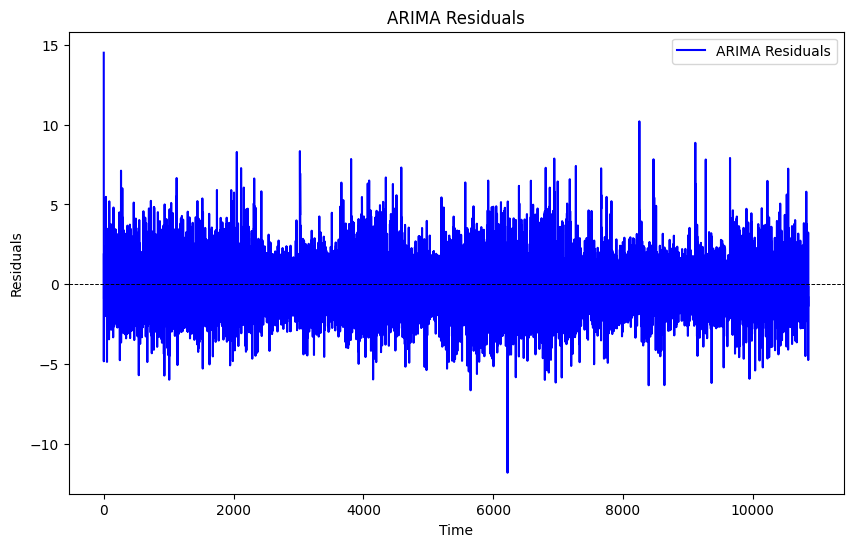

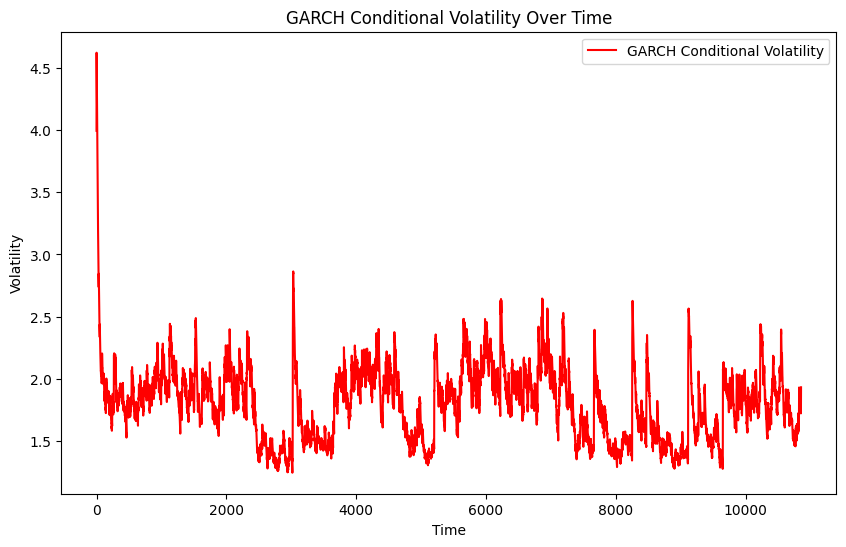

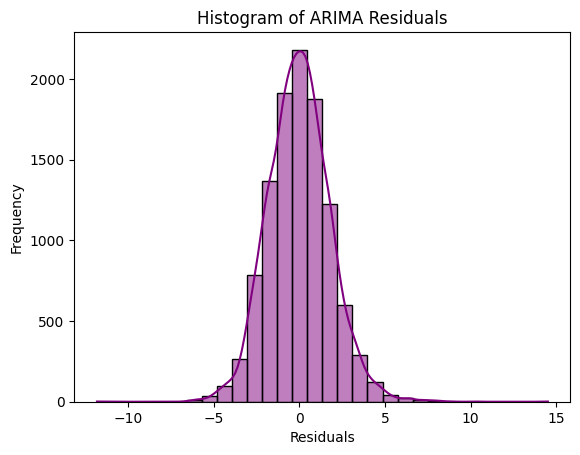

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot ARIMA residuals
plt.figure(figsize=(10, 6))
plt.plot(residuals, label="ARIMA Residuals", color="blue")
plt.title("ARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.axhline(0, color="black", linestyle="--", linewidth=0.7)
plt.legend()
plt.show()

# Plot GARCH conditional volatilities
plt.figure(figsize=(10, 6))
plt.plot(conditional_volatilities, label="GARCH Conditional Volatility", color="red")
plt.title("GARCH Conditional Volatility Over Time")
plt.xlabel("Time")
plt.ylabel("Volatility")
plt.legend()
plt.show()

# Residual histogram for normality
sns.histplot(residuals, kde=True, color="purple", bins=30)
plt.title("Histogram of ARIMA Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()


Plot: Heatmap Sector

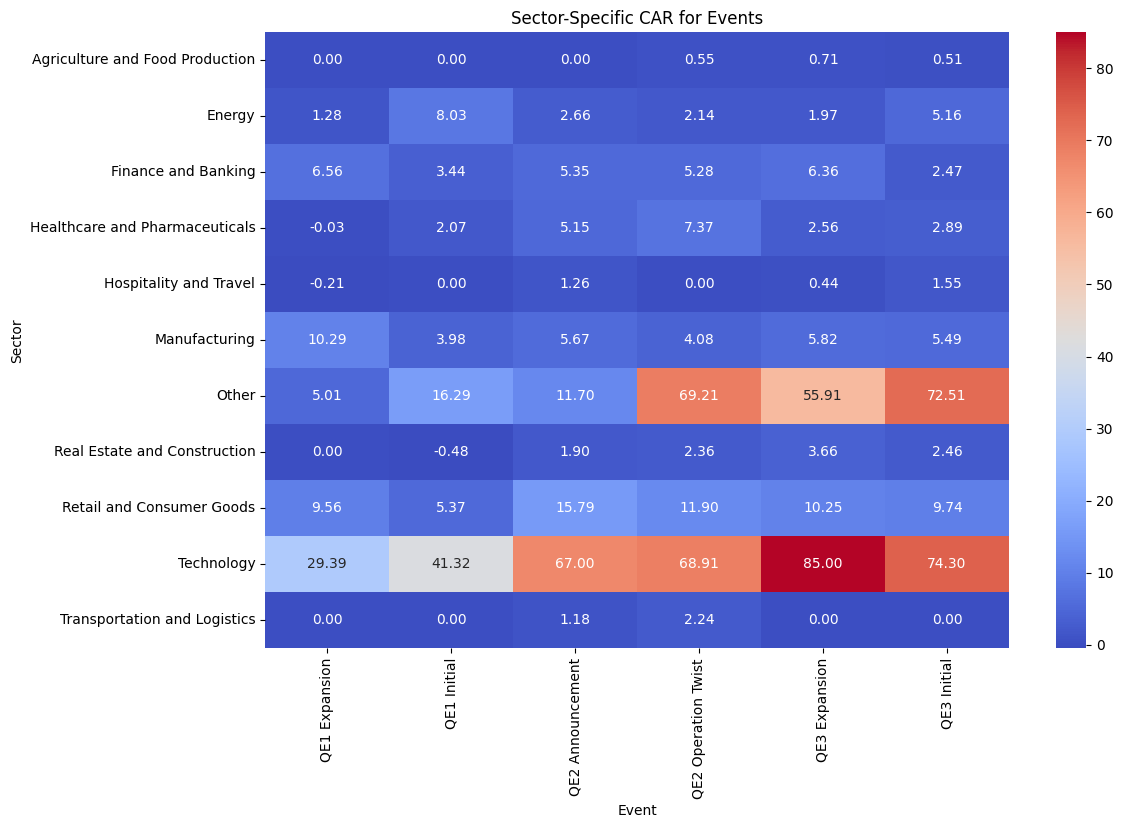

In [ ]:
import seaborn as sns


# Pivot data for heatmap
sector_performance = results_df.pivot_table(
    index='Sector',
    columns='Event',
    values='CAR',
    aggfunc='mean'
).fillna(0)

# Heatmap for CAR by sector and event
plt.figure(figsize=(12, 8))
sns.heatmap(sector_performance, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Sector-Specific CAR for Events")
plt.xlabel("Event")
plt.ylabel("Sector")
plt.show()


Plot: Heatmap Funding Type

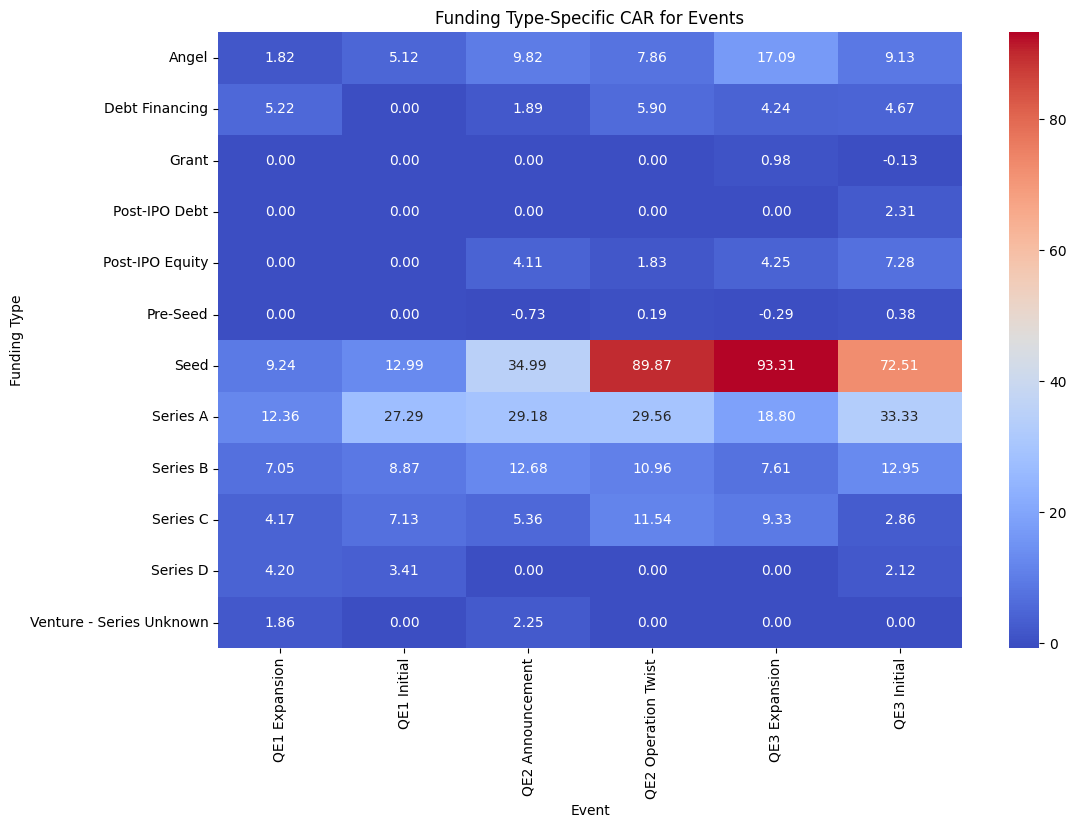

In [ ]:
# Pivot data for heatmap: Funding Type Performance
funding_type_performance = results_df.pivot_table(
    index='Funding Type',
    columns='Event',
    values='CAR',
    aggfunc='mean'
).fillna(0)

# Heatmap for CAR by funding type and event
plt.figure(figsize=(12, 8))
sns.heatmap(funding_type_performance, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Funding Type-Specific CAR for Events")
plt.xlabel("Event")
plt.ylabel("Funding Type")
plt.show()


CAR over across windows

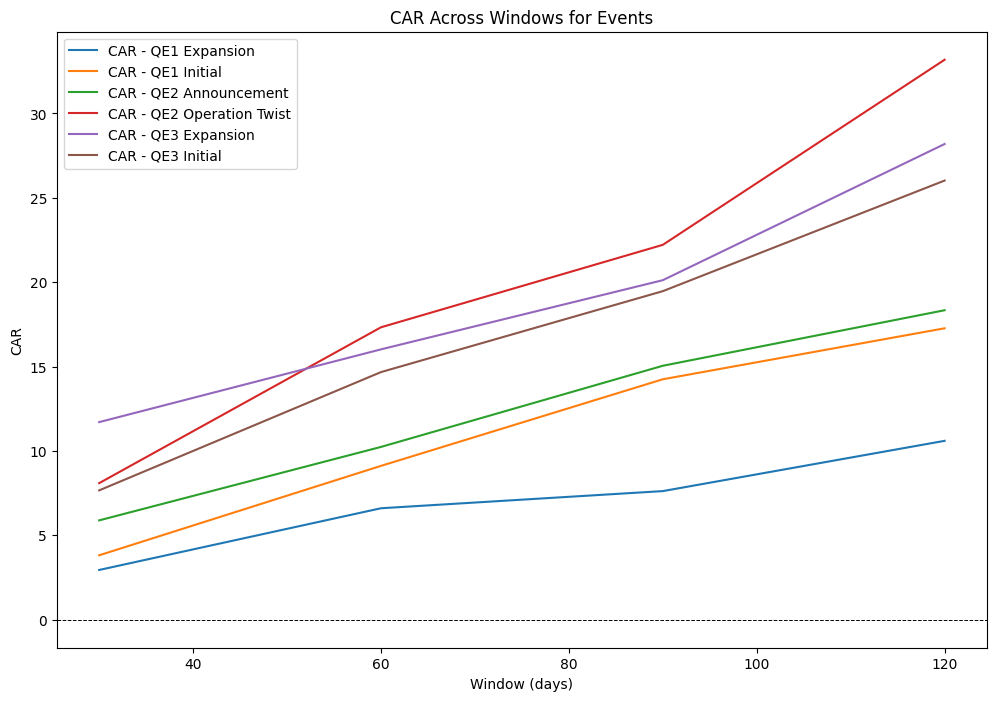

In [ ]:
import matplotlib.pyplot as plt

# Aggregate results by window and event for visualization (CAR only)
car_summary = results_df.groupby(['Event', 'Window']).agg({
    'CAR': 'mean'
}).reset_index()

# Plot CAR
plt.figure(figsize=(12, 8))
for event in car_summary['Event'].unique():
    event_data = car_summary[car_summary['Event'] == event]
    plt.plot(event_data['Window'], event_data['CAR'], label=f"CAR - {event}")

plt.title("CAR Across Windows for Events")
plt.xlabel("Window (days)")
plt.ylabel("CAR")
plt.axhline(0, color="black", linestyle="--", linewidth=0.7)
plt.legend()
plt.show()



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create directory to save outputs
output_dir = "thesis_outputs"
os.makedirs(output_dir, exist_ok=True)

# Plot 1: ARIMA residuals
plt.figure(figsize=(10, 6))
plt.plot(residuals, label="ARIMA Residuals", color="blue")
plt.title("ARIMA Residuals")
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.axhline(0, color="black", linestyle="--", linewidth=0.7)
plt.legend()
plt.savefig(os.path.join(output_dir, "arima_residuals.png"))
plt.close()

# Plot 2: GARCH conditional volatilities
plt.figure(figsize=(10, 6))
plt.plot(conditional_volatilities, label="GARCH Conditional Volatility", color="red")
plt.title("GARCH Conditional Volatility Over Time")
plt.xlabel("Time")
plt.ylabel("Volatility")
plt.legend()
plt.savefig(os.path.join(output_dir, "garch_volatility.png"))
plt.close()

# Plot 3: Residual histogram for normality
plt.figure(figsize=(10, 6))
sns.histplot(residuals, kde=True, color="purple", bins=30)
plt.title("Histogram of ARIMA Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.savefig(os.path.join(output_dir, "residual_histogram.png"))
plt.close()

# Plot 4: Funding Type Heatmap
funding_type_performance = results_df.pivot_table(
    index='Funding Type',
    columns='Event',
    values='CAR',
    aggfunc='mean'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(funding_type_performance, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Funding Type-Specific CAR for Events")
plt.xlabel("Event")
plt.ylabel("Funding Type")
plt.savefig(os.path.join(output_dir, "funding_type_heatmap.png"))
plt.close()

# Plot 5: Sector Performance Heatmap
sector_performance = results_df.pivot_table(
    index='Sector',
    columns='Event',
    values='CAR',
    aggfunc='mean'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(sector_performance, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Sector-Specific CAR for Events")
plt.xlabel("Event")
plt.ylabel("Sector")
plt.savefig(os.path.join(output_dir, "sector_heatmap.png"))
plt.close()

# Plot 6: CAR and CAAR across windows for events
car_caar_summary = results_df.groupby(['Event', 'Window']).agg({
    'CAR': 'mean',
    'CAAR': 'mean',
    'P_Value_MannWhitney': 'mean'
}).reset_index()

plt.figure(figsize=(12, 8))
for event in car_caar_summary['Event'].unique():
    event_data = car_caar_summary[car_caar_summary['Event'] == event]
    plt.plot(event_data['Window'], event_data['CAR'], label=f"CAR - {event}")
    plt.plot(event_data['Window'], event_data['CAAR'], label=f"CAAR - {event}", linestyle="--")

plt.title("CAR and CAAR Across Windows for Events")
plt.xlabel("Window (days)")
plt.ylabel("CAR / CAAR")
plt.axhline(0, color="black", linestyle="--", linewidth=0.7)
plt.legend()
plt.savefig(os.path.join(output_dir, "car_caar_windows.png"))
plt.close()

# Save important data summaries to Excel
results_df.to_excel(os.path.join(output_dir, "event_study_results.xlsx"), index=False)

print(f"All outputs have been saved to the directory: {output_dir}")


All outputs have been saved to the directory: thesis_outputs


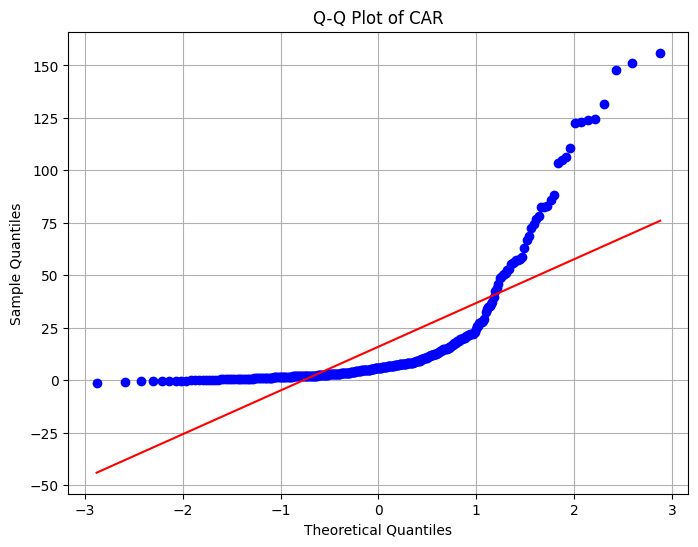

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# Assuming 'results_df' contains the CAR values from the event study
# Replace 'CAR' with the actual column name containing the CAR data
car_values = results_df['CAR'].dropna()  # Drop any missing values

# Q-Q plot for CAR
plt.figure(figsize=(8, 6))
stats.probplot(car_values, dist="norm", plot=plt)
plt.title("Q-Q Plot of CAR")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles")
plt.grid()
plt.show()


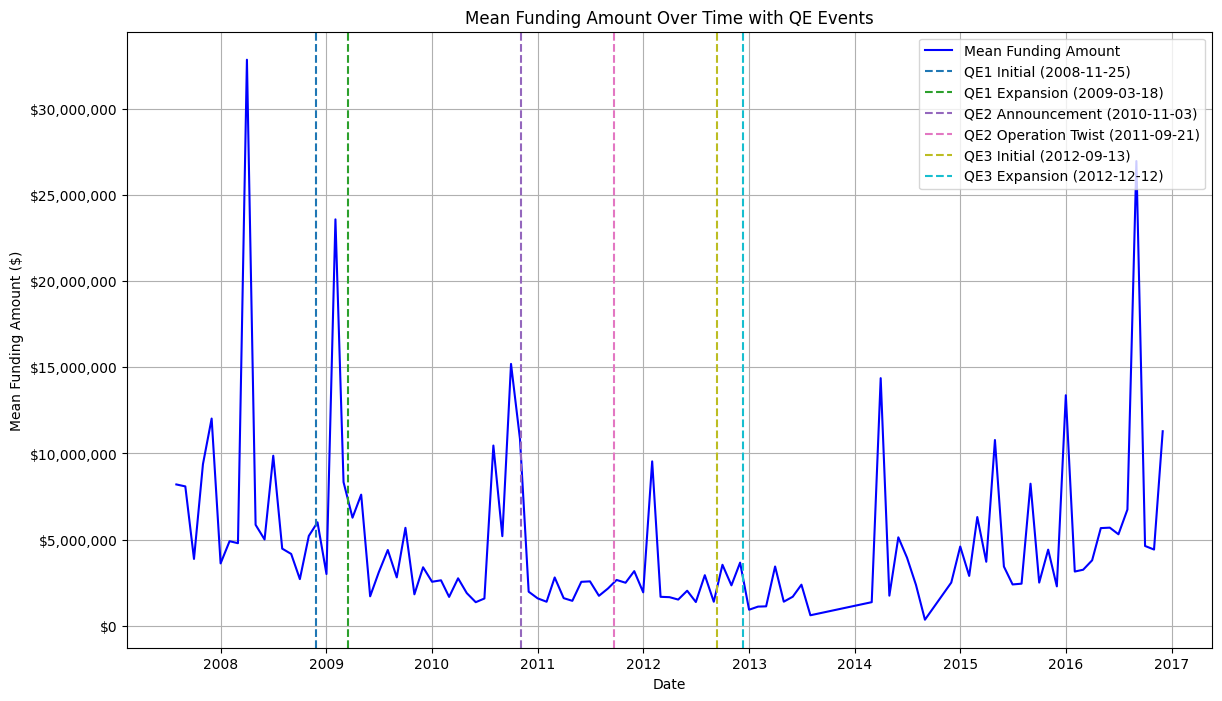

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
from matplotlib.ticker import FuncFormatter

# Function to format y-axis as dollars
def format_dollars(x, pos):
    return f'${x:,.0f}'

# Aggregate funding data over time (non-sector-specific)
data['Year-Month'] = data['Last Funding Date'].dt.to_period('M')
funding_over_time = data.groupby('Year-Month')['Last Funding Amount'].mean().reset_index()
funding_over_time['Year-Month'] = funding_over_time['Year-Month'].dt.to_timestamp()

# Generate unique colors for each event
colors = cm.tab10(np.linspace(0, 1, len(event_dates)))

# Plot funding amounts over time
plt.figure(figsize=(14, 8))
plt.plot(funding_over_time['Year-Month'], funding_over_time['Last Funding Amount'], label="Mean Funding Amount", color="blue")

# Mark QE events with different colors
for (event_name, event_date), color in zip(event_dates.items(), colors):
    plt.axvline(event_date, color=color, linestyle='--', label=f"{event_name} ({event_date.strftime('%Y-%m-%d')})")

# Add dollar formatting to the y-axis
plt.gca().yaxis.set_major_formatter(FuncFormatter(format_dollars))

plt.title("Mean Funding Amount Over Time with QE Events")
plt.xlabel("Date")
plt.ylabel("Mean Funding Amount ($)")
plt.legend()
plt.grid()
plt.show()



## Heatmaps Funding Type & Sector, 30 & 120 Event Window

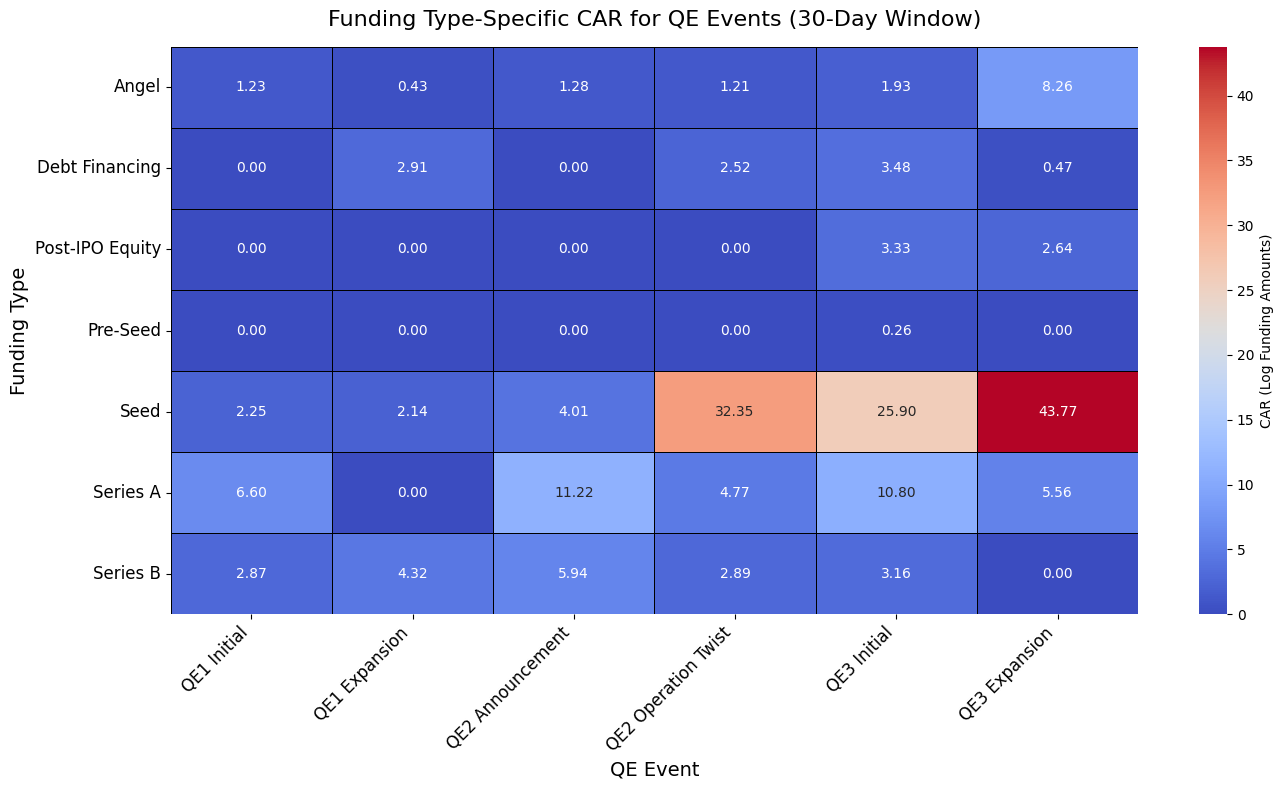

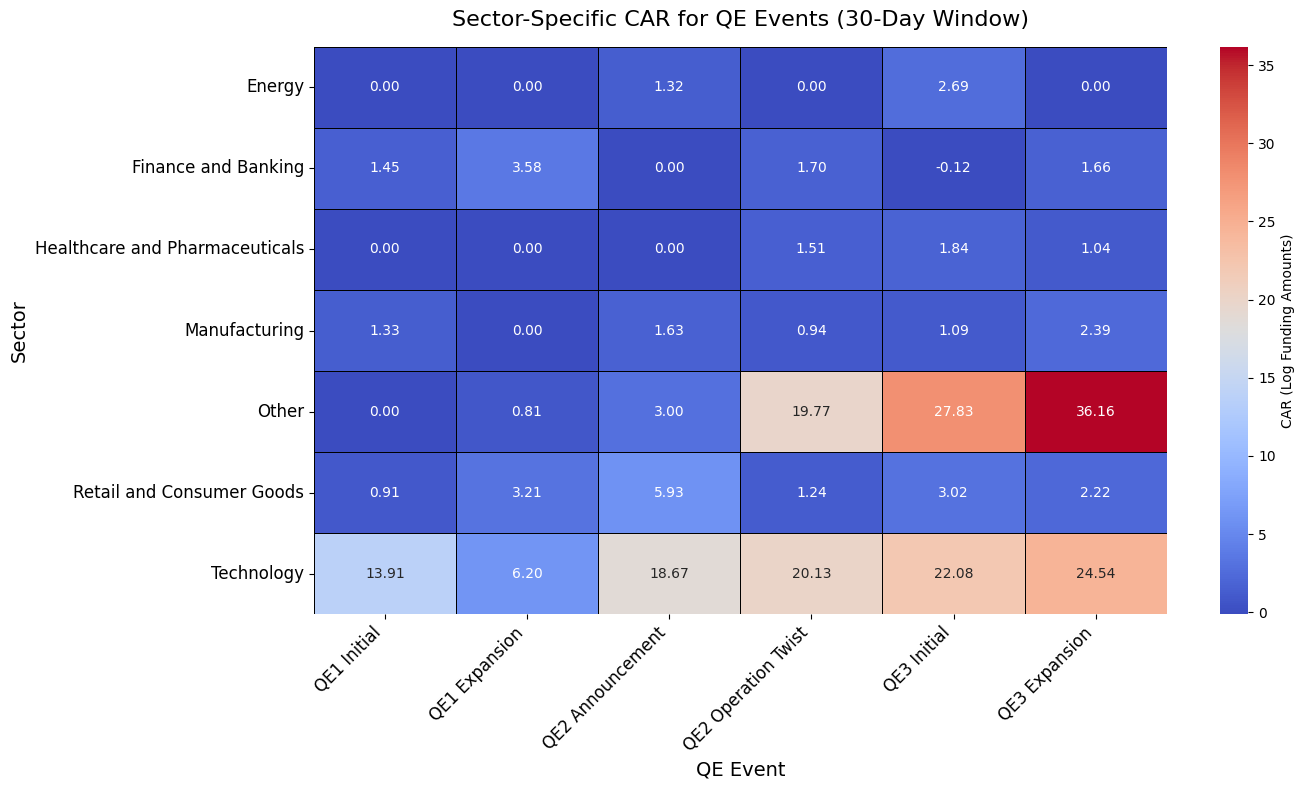

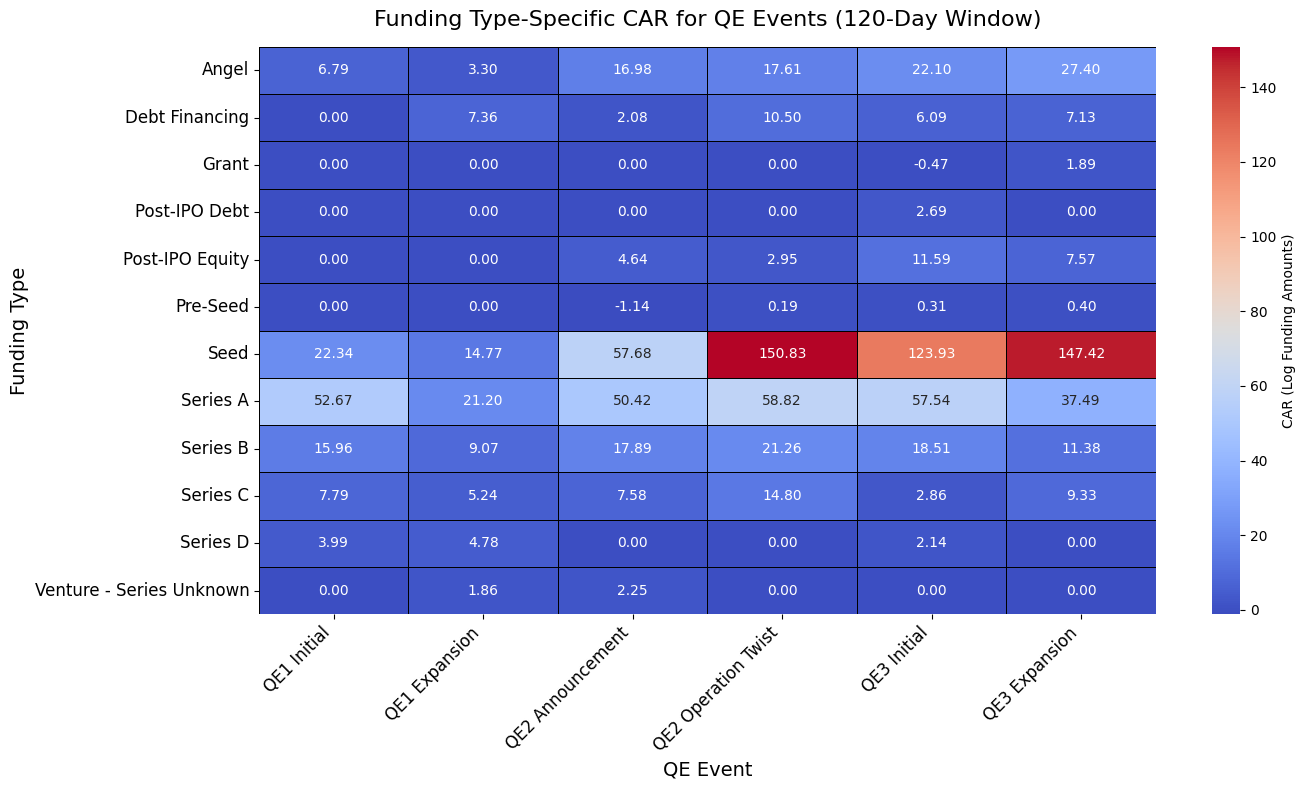

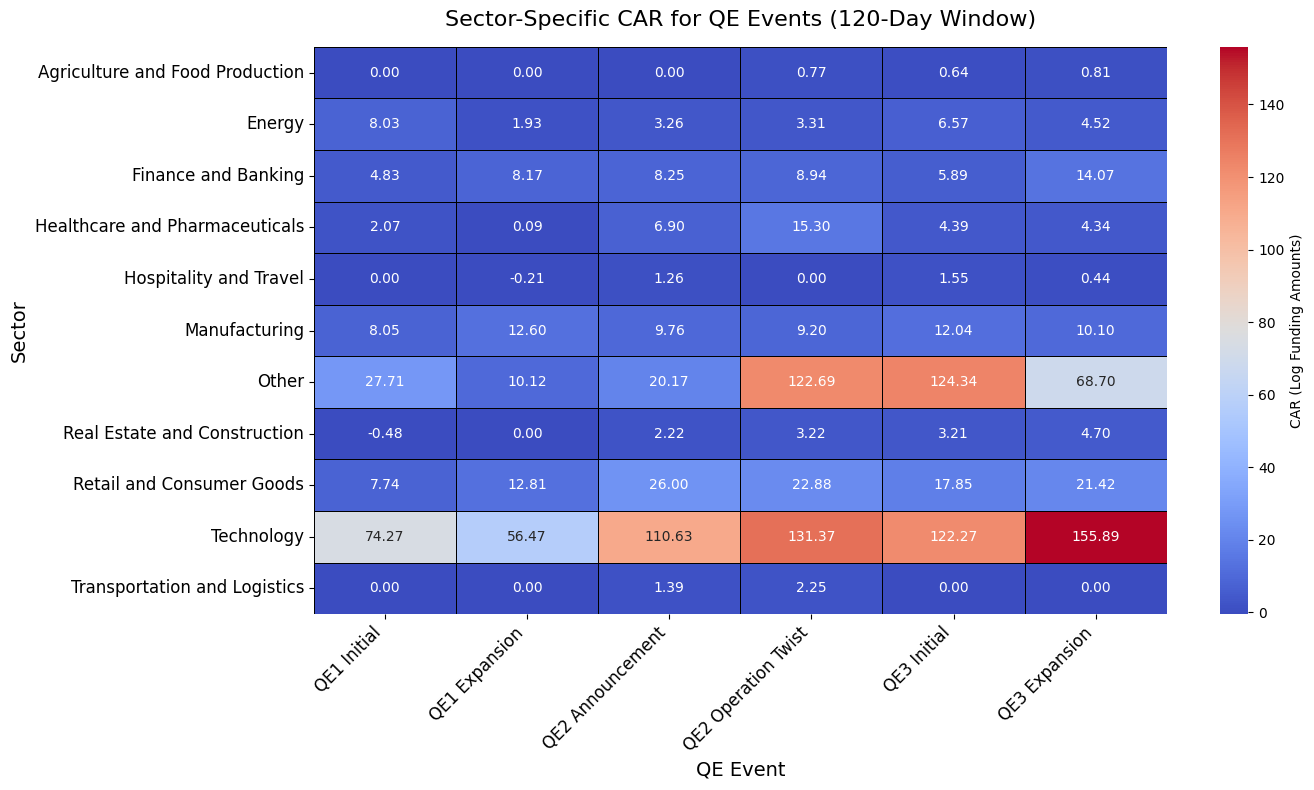

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define QE event dates and windows
event_dates = {
    'QE1 Initial': '2008-11-25',
    'QE1 Expansion': '2009-03-18',
    'QE2 Announcement': '2010-11-03',
    'QE2 Operation Twist': '2011-09-21',
    'QE3 Initial': '2012-09-13',
    'QE3 Expansion': '2012-12-12'
}
ordered_events = sorted(event_dates.keys(), key=lambda x: event_dates[x])

# Filter data for the 30-day window
window_30 = 30
filtered_data_30 = results_df[results_df['Window'] == window_30]

# Pivot data for Funding Type heatmap (30-day window)
funding_type_performance_30 = filtered_data_30.pivot_table(
    index='Funding Type',
    columns='Event',
    values='CAR',
    aggfunc='mean'
).fillna(0)

funding_type_performance_30 = funding_type_performance_30[ordered_events]

# Plot Funding Type heatmap (30-day window)
plt.figure(figsize=(14, 8))
sns.heatmap(
    funding_type_performance_30,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    linecolor="black",
    cbar_kws={"label": "CAR (Log Funding Amounts)"}
)
plt.title("Funding Type-Specific CAR for QE Events (30-Day Window)", fontsize=16, pad=15)
plt.xlabel("QE Event", fontsize=14)
plt.ylabel("Funding Type", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

# Pivot data for Sector heatmap (30-day window)
sector_performance_30 = filtered_data_30.pivot_table(
    index='Sector',
    columns='Event',
    values='CAR',
    aggfunc='mean'
).fillna(0)

sector_performance_30 = sector_performance_30[ordered_events]

# Plot Sector heatmap (30-day window)
plt.figure(figsize=(14, 8))
sns.heatmap(
    sector_performance_30,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    linecolor="black",
    cbar_kws={"label": "CAR (Log Funding Amounts)"}
)
plt.title("Sector-Specific CAR for QE Events (30-Day Window)", fontsize=16, pad=15)
plt.xlabel("QE Event", fontsize=14)
plt.ylabel("Sector", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

# Filter data for the 120-day window
window_120 = 120
filtered_data_120 = results_df[results_df['Window'] == window_120]

# Pivot data for Funding Type heatmap (120-day window)
funding_type_performance_120 = filtered_data_120.pivot_table(
    index='Funding Type',
    columns='Event',
    values='CAR',
    aggfunc='mean'
).fillna(0)

funding_type_performance_120 = funding_type_performance_120[ordered_events]

# Plot Funding Type heatmap (120-day window)
plt.figure(figsize=(14, 8))
sns.heatmap(
    funding_type_performance_120,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    linecolor="black",
    cbar_kws={"label": "CAR (Log Funding Amounts)"}
)
plt.title("Funding Type-Specific CAR for QE Events (120-Day Window)", fontsize=16, pad=15)
plt.xlabel("QE Event", fontsize=14)
plt.ylabel("Funding Type", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

# Pivot data for Sector heatmap (120-day window)
sector_performance_120 = filtered_data_120.pivot_table(
    index='Sector',
    columns='Event',
    values='CAR',
    aggfunc='mean'
).fillna(0)

sector_performance_120 = sector_performance_120[ordered_events]

# Plot Sector heatmap (120-day window)
plt.figure(figsize=(14, 8))
sns.heatmap(
    sector_performance_120,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    linecolor="black",
    cbar_kws={"label": "CAR (Log Funding Amounts)"}
)
plt.title("Sector-Specific CAR for QE Events (120-Day Window)", fontsize=16, pad=15)
plt.xlabel("QE Event", fontsize=14)
plt.ylabel("Sector", fontsize=14)
plt.xticks(rotation=45, ha="right", fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


CAR TESTS

TESTS
- EVENT WINDOW - CAR
- EVENT WINDOW + QE EVENT - CAR
- EVENT WINDOW + QE EVENT + SECTOR  - CAR
- EVENT WINDOW + QE EVENT + FUNDING TYPE - CAR

Causal Inference:

- A correlation between QE events and funding amounts
  does not imply causation. Add robustness checks, such as placebo tests (using fake QE event dates) or testing for confounding factors that might also influence funding amounts.

Statistical Robustness:

- Multiple testing can lead to inflated Type I errors
  (false positives). Consider adjustments like Bonferroni correction or False Discovery Rate (FDR) if you conduct many statistical tests.

2. Event Study

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_ind, mannwhitneyu, kruskal, f_oneway
from sklearn.utils import resample
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

# Load and prepare the dataset
data = pd.read_csv("data.csv")
data['Last Funding Date'] = pd.to_datetime(data['Last Funding Date'])

data['log_Last_Funding_Amount'] = np.log(data['Last Funding Amount'] + 1)

data['Last Funding Date'] = pd.to_datetime(data['Last Funding Date'])


event_dates = {
    "QE1 Initial": "2008-12-16",
    "QE1 Expansion": "2009-03-18",
    "QE2 Announcement": "2010-11-03",
    "QE2 Operation Twist": "2011-09-21",
    "QE3 Initial": "2012-09-13",
    "QE3 Expansion": "2012-12-12",
}

# Convert all event dates to datetime objects
event_dates = {event: pd.to_datetime(date) for event, date in event_dates.items()}

event_windows = [30, 60, 90, 120]

# Placeholder for results
results = []

# Analysis Loop
for window in event_windows:
    for event_name, event_date in event_dates.items():

        # Event Window - CAR
        pre_event_data = data[
            (data['Last Funding Date'] >= event_date - pd.Timedelta(days=window)) &
            (data['Last Funding Date'] < event_date)
        ]['log_Last_Funding_Amount']

        post_event_data = data[
            (data['Last Funding Date'] >= event_date) &
            (data['Last Funding Date'] <= event_date + pd.Timedelta(days=window))
        ]['log_Last_Funding_Amount']

        if len(pre_event_data) >= 2 and len(post_event_data) >= 2:
            # Welch's t-test
            t_stat, p_value_t = ttest_ind(pre_event_data, post_event_data, equal_var=False)

            # Mann-Whitney U Test
            _, p_value_mwu = mannwhitneyu(pre_event_data, post_event_data, alternative='two-sided')

            # CAR Calculation
            car = post_event_data.sum() - pre_event_data.sum()
            caar = (post_event_data.mean() - pre_event_data.mean())

            results.append({
                'Event': event_name,
                'Window': window,
                'CAR': car,
                'CAAR': caar,
                'P-Value Welch': p_value_t,
                'P-Value Mann-Whitney': p_value_mwu,
                'Category': 'Event Window'
            })

        # Event Window + QE Event + Sector
        for sector in data['Sector'].unique():
            sector_data = data[data['Sector'] == sector]

            pre_event_data = sector_data[
                (sector_data['Last Funding Date'] >= event_date - pd.Timedelta(days=window)) &
                (sector_data['Last Funding Date'] < event_date)
            ]['log_Last_Funding_Amount']

            post_event_data = sector_data[
                (sector_data['Last Funding Date'] >= event_date) &
                (sector_data['Last Funding Date'] <= event_date + pd.Timedelta(days=window))
            ]['log_Last_Funding_Amount']

            if len(pre_event_data) >= 2 and len(post_event_data) >= 2:
                # Kruskal-Wallis Test
                _, p_value_kruskal = kruskal(pre_event_data, post_event_data)

                # CAR Calculation
                car = post_event_data.sum() - pre_event_data.sum()
                caar = (post_event_data.mean() - pre_event_data.mean())

                results.append({
                    'Event': event_name,
                    'Window': window,
                    'Sector': sector,
                    'CAR': car,
                    'CAAR': caar,
                    'P-Value Kruskal': p_value_kruskal,
                    'Category': 'Event Window + QE Event + Sector'
                })

        # Event Window + QE Event + Funding Type
        for funding_type in data['Last Funding Type'].unique():
            funding_type_data = data[data['Last Funding Type'] == funding_type]

            pre_event_data = funding_type_data[
                (funding_type_data['Last Funding Date'] >= event_date - pd.Timedelta(days=window)) &
                (funding_type_data['Last Funding Date'] < event_date)
            ]['log_Last_Funding_Amount']

            post_event_data = funding_type_data[
                (funding_type_data['Last Funding Date'] >= event_date) &
                (funding_type_data['Last Funding Date'] <= event_date + pd.Timedelta(days=window))
            ]['log_Last_Funding_Amount']

            if len(pre_event_data) >= 2 and len(post_event_data) >= 2:
                # ANOVA Test
                f_stat, p_value_anova = f_oneway(pre_event_data, post_event_data)

                # CAR Calculation
                car = post_event_data.sum() - pre_event_data.sum()
                caar = (post_event_data.mean() - pre_event_data.mean())

                results.append({
                    'Event': event_name,
                    'Window': window,
                    'Funding Type': funding_type,
                    'CAR': car,
                    'CAAR': caar,
                    'P-Value ANOVA': p_value_anova,
                    'Category': 'Event Window + QE Event + Funding Type'
                })

# Convert results to DataFrame
results_df = pd.DataFrame(results)

# Adjust p-values for multiple comparisons
p_columns = [col for col in results_df.columns if 'P-Value' in col]
for col in p_columns:
    results_df[f'{col} (Adj)'] = multipletests(results_df[col], method='fdr_bh')[1]

# Save results
results_df.to_excel("2.Event_Study_Results.xlsx", index=False)

print("Event study analysis completed and saved.")


Event study analysis completed and saved.


Plots for 2. Event Study

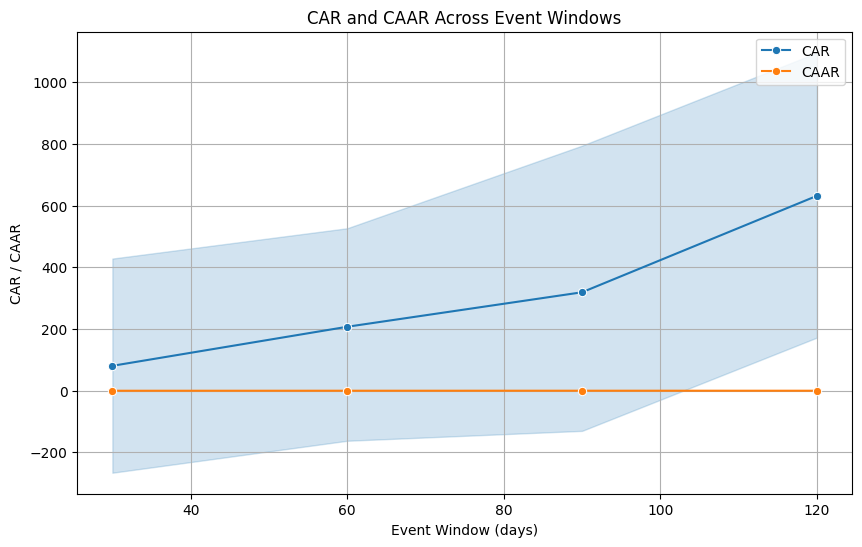

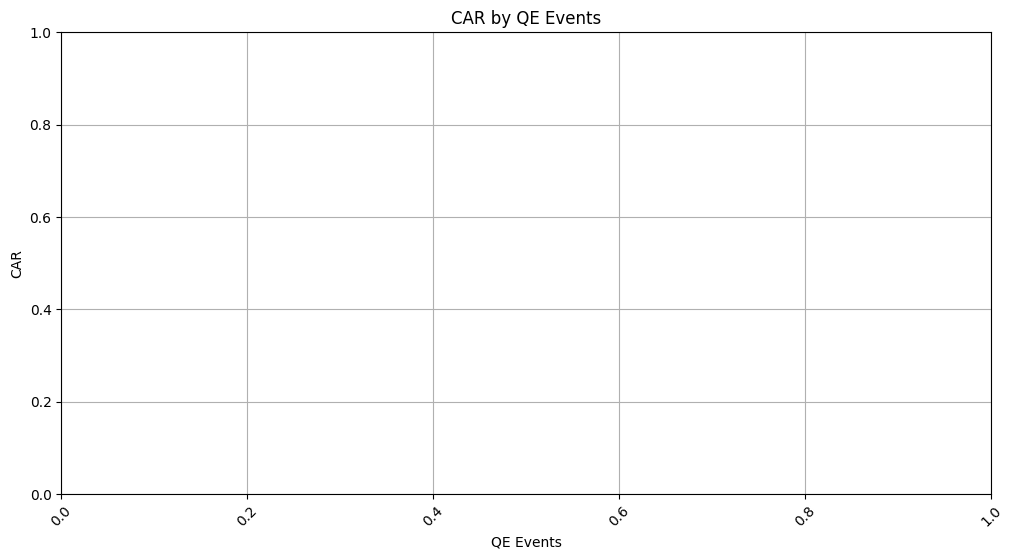

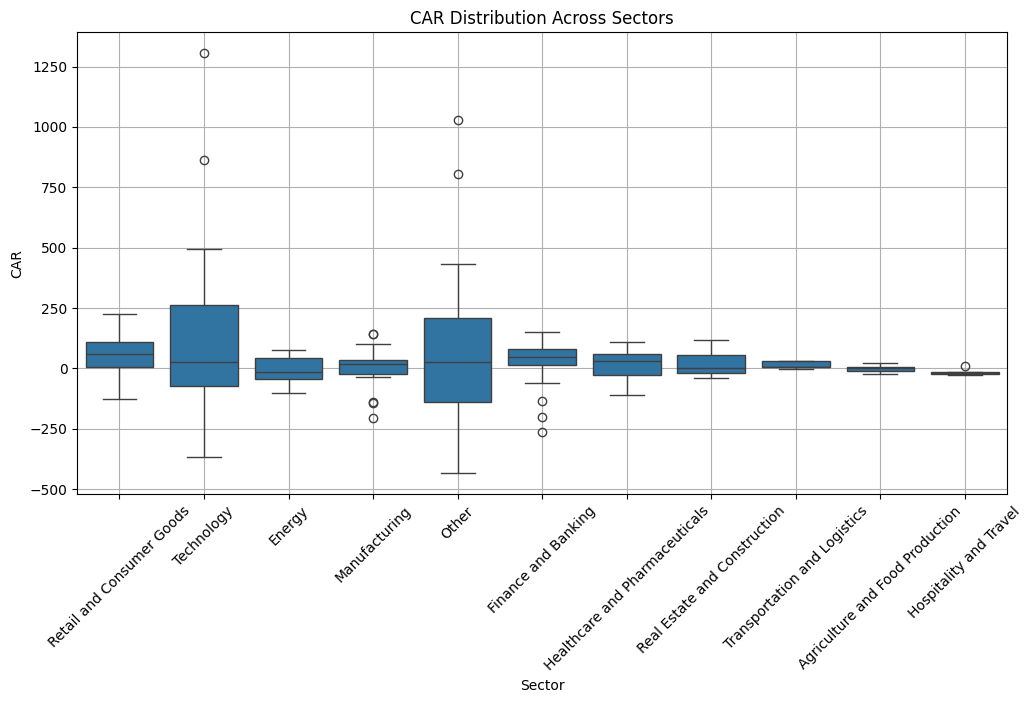

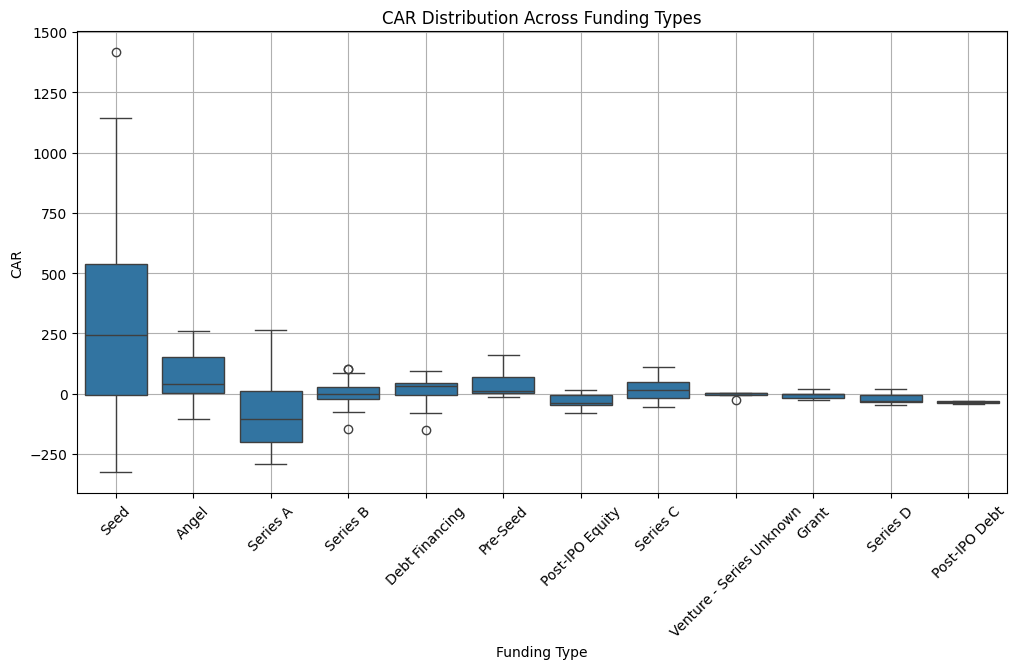

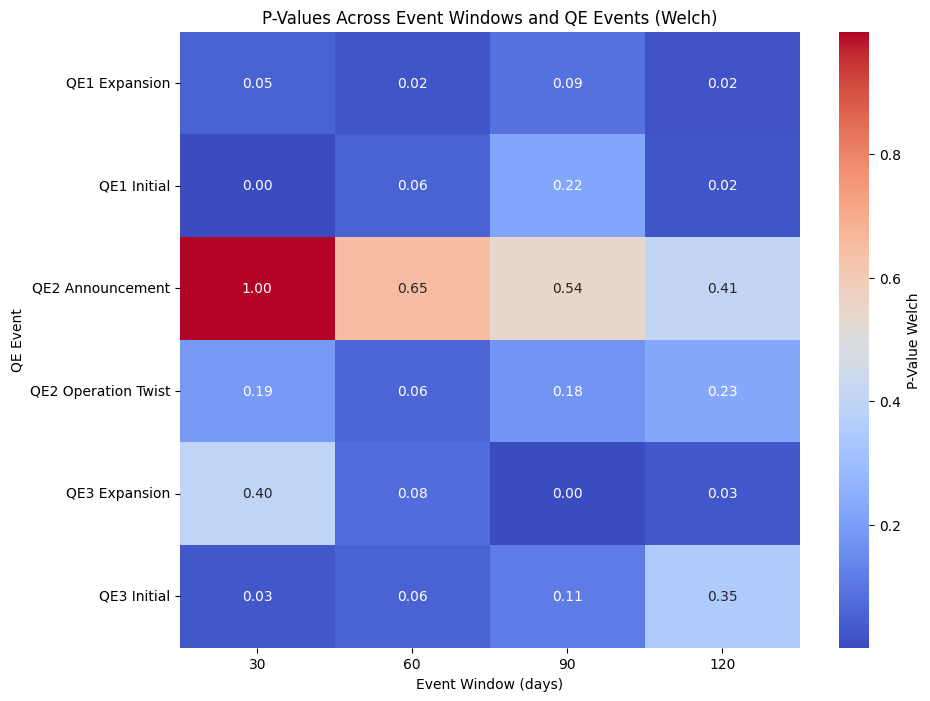

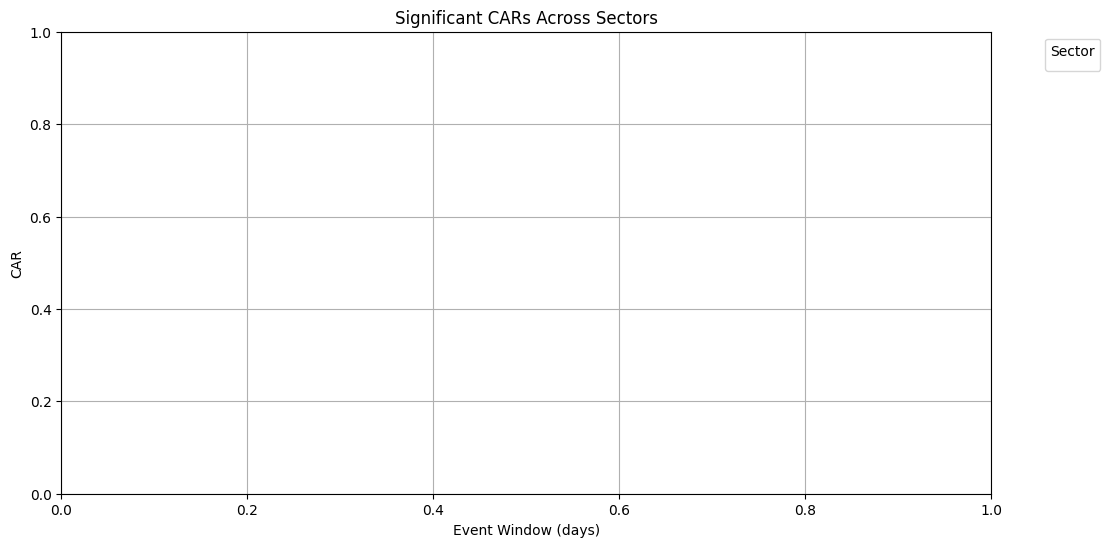

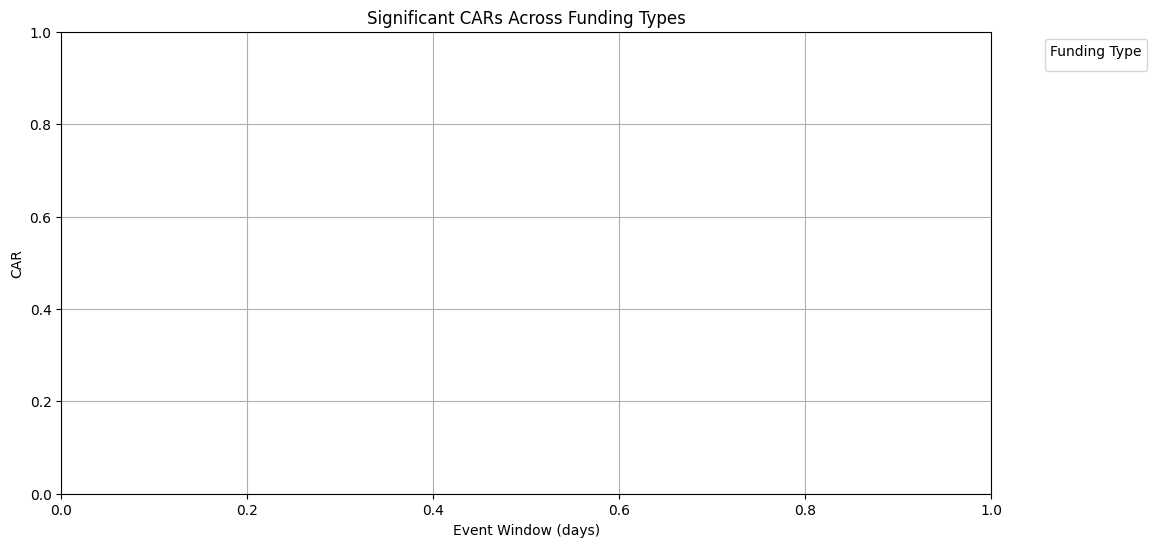

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the results file
# results = pd.read_excel("Event_Study_Results.xlsx")

# Ensure columns are correctly interpreted
results['Window'] = results['Window'].astype(int)
results['CAR'] = results['CAR'].astype(float)
results['CAAR'] = results['CAAR'].astype(float)

# Filter significant results
significant_results = results[
    (results['P-Value Welch'] < 0.05) |
    (results['P-Value Mann-Whitney'] < 0.05)
]

# 1. Plot CAR and CAAR over Event Windows
plt.figure(figsize=(10, 6))
sns.lineplot(data=results[results['Category'] == 'Event Window'], x='Window', y='CAR', marker='o', label='CAR')
sns.lineplot(data=results[results['Category'] == 'Event Window'], x='Window', y='CAAR', marker='o', label='CAAR')
plt.title('CAR and CAAR Across Event Windows')
plt.xlabel('Event Window (days)')
plt.ylabel('CAR / CAAR')
plt.legend()
plt.grid()
plt.savefig('CAR_CAAR_Event_Window.png')
plt.show()

# 2. Bar Plot of CAR by QE Event
plt.figure(figsize=(12, 6))
sns.barplot(data=results[results['Category'] == 'Event Window + QE Event'], x='Event', y='CAR', ci=None)
plt.title('CAR by QE Events')
plt.xlabel('QE Events')
plt.ylabel('CAR')
plt.xticks(rotation=45)
plt.grid()
plt.savefig('CAR_by_QE_Events.png')
plt.show()

# 3. Box Plot of CAR by Sector
plt.figure(figsize=(12, 6))
sns.boxplot(data=results[results['Category'] == 'Event Window + QE Event + Sector'], x='Sector', y='CAR')
plt.title('CAR Distribution Across Sectors')
plt.xlabel('Sector')
plt.ylabel('CAR')
plt.xticks(rotation=45)
plt.grid()
plt.savefig('CAR_by_Sector.png')
plt.show()

# 4. Box Plot of CAR by Funding Type
plt.figure(figsize=(12, 6))
sns.boxplot(data=results[results['Category'] == 'Event Window + QE Event + Funding Type'], x='Funding Type', y='CAR')
plt.title('CAR Distribution Across Funding Types')
plt.xlabel('Funding Type')
plt.ylabel('CAR')
plt.xticks(rotation=45)
plt.grid()
plt.savefig('CAR_by_Funding_Type.png')
plt.show()

# 5. Heatmap of P-Values Across Event Windows and QE Events
heatmap_data = results.pivot_table(
    values='P-Value Welch',
    index='Event',
    columns='Window',
    aggfunc='mean'
)
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap='coolwarm', cbar_kws={'label': 'P-Value Welch'})
plt.title('P-Values Across Event Windows and QE Events (Welch)')
plt.xlabel('Event Window (days)')
plt.ylabel('QE Event')
plt.savefig('P_Values_Heatmap.png')
plt.show()

# 6. Line Plot of Significant CARs Across Sectors
significant_sectors = significant_results[significant_results['Category'] == 'Event Window + QE Event + Sector']
plt.figure(figsize=(12, 6))
sns.lineplot(data=significant_sectors, x='Window', y='CAR', hue='Sector', marker='o')
plt.title('Significant CARs Across Sectors')
plt.xlabel('Event Window (days)')
plt.ylabel('CAR')
plt.legend(title='Sector', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.savefig('Significant_CARs_by_Sector.png')
plt.show()

# 7. Line Plot of Significant CARs Across Funding Types
significant_funding = significant_results[significant_results['Category'] == 'Event Window + QE Event + Funding Type']
plt.figure(figsize=(12, 6))
sns.lineplot(data=significant_funding, x='Window', y='CAR', hue='Funding Type', marker='o')
plt.title('Significant CARs Across Funding Types')
plt.xlabel('Event Window (days)')
plt.ylabel('CAR')
plt.legend(title='Funding Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid()
plt.savefig('Significant_CARs_by_Funding_Type.png')
plt.show()
